# A lattice of high-index rods: multipoles, lattice sums and bands

The test structure for this folder is the simplest all-dielectric "magnetic" metamaterial: a square lattice of circular rods with a large permittivity, in two dimensions. Nothing in it is magnetic. A rod has Mie resonances in which the displacement current circulates, and near them the lattice is commonly assigned a permeability. This notebook sets up the exact solver used in notebooks 03 and 04, validates it, and looks at where the resonances fall in the band structure, since that decides whether a description by local parameters has a chance.

## What this notebook shows

- The scattering coefficients of one rod in both polarizations and which of them are magnetic dipoles. The two magnetic-dipole coefficients (dipole along the rod for TE, dipole in the plane for TM) are the same function of frequency for nonmagnetic rods, $t^{\rm TE}_0=t^{\rm TM}_1$, and their resonance tends to $k_0R\sqrt{\varepsilon_r}=2.405$ in the high-index limit.
- Lattice sums for the square lattice from a rapidly convergent plane-wave form, checked against brute-force sums at complex frequency.
- Bloch modes from a Hermitian form of the multiple-scattering condition, with multiplicities, checked against an independent plane-wave calculation.
- Band structures for $\varepsilon_r=12$ and $\varepsilon_r=100$. With $\varepsilon_r=12$ the magnetic resonance sits where the Bloch wavelength is about two periods; with $\varepsilon_r=100$ it sits at a vacuum wavelength of about eight periods and opens a gap in the middle of the Brillouin zone.
- The textbook local model for TE, a static permittivity and the O'Brien-Pendry permeability, against the exact bands.

## Conventions

Time dependence $e^{-i\omega t}$, so outgoing cylindrical waves are $H_m\equiv H^{(1)}_m$. Lengths are in units of the lattice period, $a=1$, and frequency is quoted as $f=a/\lambda_0=k_0a/2\pi$ (this folder sweeps frequency, so the period and not the wavelength is the unit). $\varepsilon_0=\mu_0=c=1$. TM is the polarization with $\mathbf E$ along the rods ($u=E_z$), TE the one with $\mathbf H$ along the rods ($u=H_z$), as in `docs/DESIGN.md`. The rods have radius $R=0.3$ (filling fraction $\eta=\pi R^2/a^2=0.283$; $f$ is always the frequency) and $\mu=1$. The solver is `rodlattice.py` in this folder.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # rodlattice.py sits next to this notebook
import rodlattice as rl
from scipy.special import jv, j1, hankel1
from scipy.optimize import brentq
from scipy.linalg import eigh

TWO_PI = 2 * np.pi
R = 0.3
FILL = np.pi * R**2

## 1. One rod

Around a rod the field is $u=\sum_m[a_mJ_m(k_0r)+b_mH_m(k_0r)]e^{im\varphi}$ outside and $\sum_mc_mJ_m(k_1r)e^{im\varphi}$ inside, $k_1=k_0\sqrt{\varepsilon_r}$. Continuity of $u$ and of $q\,\partial_ru$ ($q=1$ for TM, $q=1/\varepsilon$ for TE) gives $b_m=t_ma_m$ with

$$t_m=-\frac{q_1k_1J_m'(k_1R)J_m(k_0R)-k_0J_m(k_1R)J_m'(k_0R)}{q_1k_1J_m'(k_1R)H_m(k_0R)-k_0J_m(k_1R)H_m'(k_0R)} .$$

For a lossless rod $t_m=-p_m/(p_m+iq_m)$ with real $p_m,q_m$ (replace $H_m$ by $Y_m$ for $q_m$), so $|t_m|\le1$ with equality on resonance, $q_m=0$. What the orders are:

| | $m=0$ | $m=\pm1$ | $m=\pm2$ |
|---|---|---|---|
| TM ($E_z$) | current along $z$, uniform over the rod: electric dipole per unit length along $z$ | currents $\pm z$ on opposite sides: **magnetic dipole in the plane** | quadrupole |
| TE ($H_z$) | current circulating around the axis: **magnetic dipole along $z$** | electric dipole in the plane | quadrupole |

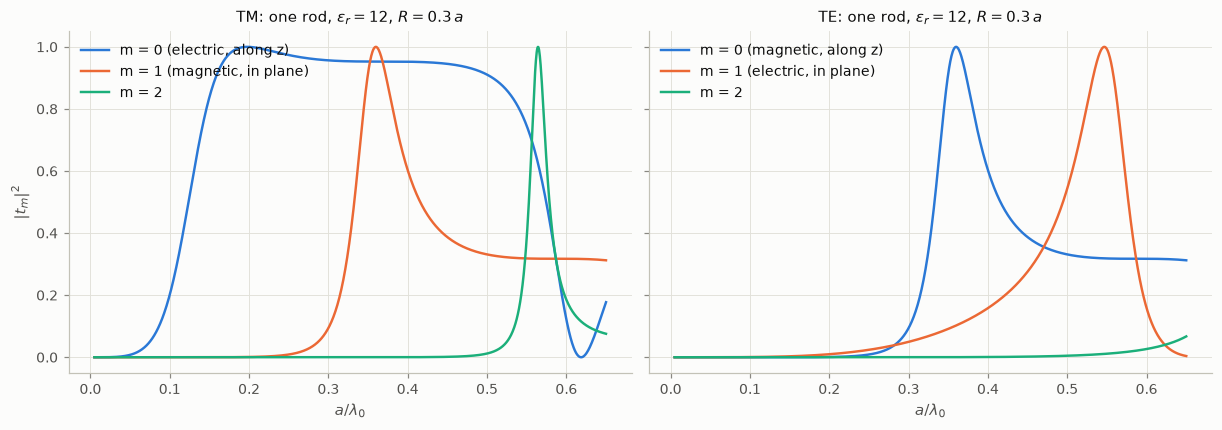

first magnetic resonance, x = k0 R sqrt(eps_r), and its frequency a/lambda0 for R = 0.3:
  eps_r     TE m=0: x      f       TM m=1: x      f       lambda0 / a at the TE resonance
     12        2.3495   0.3598        2.3495   0.3598       2.78
     30        2.3435   0.2270        2.3435   0.2270       4.41
    100        2.3705   0.1258        2.3705   0.1258       7.95
   1000        2.3984   0.0402        2.3984   0.0402      24.85
PASS  the resonance tends to the first zero of J0 (eps_r = 1000): got 2.39842, target 2.40483, |diff| 6.40e-03 <= 1e-02
PASS  t_0 (TE) = t_1 (TM) at every frequency and permittivity tried (max |difference|): got 3.99575e-16, target 0, |diff| 4.00e-16 <= 1e-13


In [3]:
def resonance(pol, m, eps, lo, hi):
    """k0 R sqrt(eps) at the resonance q_m = 0 of order m, searched between lo and hi."""
    n = np.sqrt(eps)
    g = lambda x: rl.mie_pq(np.array([m]), x / (n * R), R, eps, pol)[1][0]
    return brentq(g, lo, hi)


fgrid = np.linspace(0.005, 0.65, 1300)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, pol, names in ((axs[0], "TM", ("m = 0 (electric, along z)", "m = 1 (magnetic, in plane)", "m = 2")),
                       (axs[1], "TE", ("m = 0 (magnetic, along z)", "m = 1 (electric, in plane)", "m = 2"))):
    for m, col, name in zip((0, 1, 2), CAT, names):
        ax.plot(fgrid, [abs(rl.mie_t(np.array([m]), TWO_PI * f, R, 12.0, pol)[0]) ** 2 for f in fgrid], color=col, label=name)
    ax.set(xlabel=r"$a/\lambda_0$", title=rf"{pol}: one rod, $\varepsilon_r=12$, $R=0.3\,a$"); ax.legend(loc="upper left")
axs[0].set_ylabel(r"$|t_m|^2$")
plt.show()

print("first magnetic resonance, x = k0 R sqrt(eps_r), and its frequency a/lambda0 for R = 0.3:")
print("  eps_r     TE m=0: x      f       TM m=1: x      f       lambda0 / a at the TE resonance")
res = {}
for eps in (12.0, 30.0, 100.0, 1000.0):
    xe = resonance("TE", 0, eps, 1.5, 2.6); xm = resonance("TM", 1, eps, 1.5, 2.6)
    res[eps] = (xe, xm)
    fe, fm = xe / (TWO_PI * np.sqrt(eps) * R), xm / (TWO_PI * np.sqrt(eps) * R)
    print(f"{eps:7.0f}   {xe:11.4f}  {fe:7.4f}   {xm:11.4f}  {fm:7.4f}   {1 / fe:8.2f}")
J0_ZERO = 2.404825557695773
check("the resonance tends to the first zero of J0 (eps_r = 1000)", res[1000.0][0], 1e-2, J0_ZERO)
ident = max(abs(rl.mie_t(np.array([0]), TWO_PI * f, R, e, "TE")[0] - rl.mie_t(np.array([1]), TWO_PI * f, R, e, "TM")[0])
            for f in (0.05, 0.2, 0.36, 0.5) for e in (2.0, 12.0, 100.0 + 3.0j))
check("t_0 (TE) = t_1 (TM) at every frequency and permittivity tried (max |difference|)", ident, 1e-13)
F_RES = {eps: res[eps][0] / (TWO_PI * np.sqrt(eps) * R) for eps in res}

The two columns of the table are equal, and not by accident. With $J_1'=J_0-J_1/x$ and the same relation for $H_1$, the numerator and denominator of $t^{\rm TM}_1$ reduce to $k_1J_0(k_1R)Z_1(k_0R)-k_0J_1(k_1R)Z_0(k_0R)$ with $Z=J$ and $Z=H$, which are $k_1/k_0$ times those of $t^{\rm TE}_0$: the two magnetic-dipole coefficients are the same function. (This uses $k_1^2=\varepsilon_rk_0^2$, a nonmagnetic rod in vacuum; with a permeability in the rod the two differ.) The resonance tends to the first zero of $J_0$ as $\varepsilon_r\to\infty$, slowly. The two dipoles are different objects all the same. In TE the dipole points along the rod; a lattice of such rods can only have $\mu_{zz}$. In TM the dipole lies in the plane and comes with an electric response along $z$ that is never weak: the effective permittivity is at least the area average $1+0.283(\varepsilon_r-1)$, so the wavelength in the lattice is short long before the resonance is reached. The frequency at which the resonance occurs sets the scale of everything that follows: $\lambda_0\approx2.8\,a$ for $\varepsilon_r=12$, a photonic crystal as much as a metamaterial, and $\lambda_0\approx8\,a$ for $\varepsilon_r=100$.

The next figure shows the two modes for a single rod in a plane wave arriving from the left, at the resonance frequency. Color is the field along the rod; arrows are the other field in the plane. In TE the arrows are $\mathbf E$, proportional to the displacement current, which circulates. In TM the color is $E_z$, proportional to the current along the rod, which flows up on one side and down on the other.

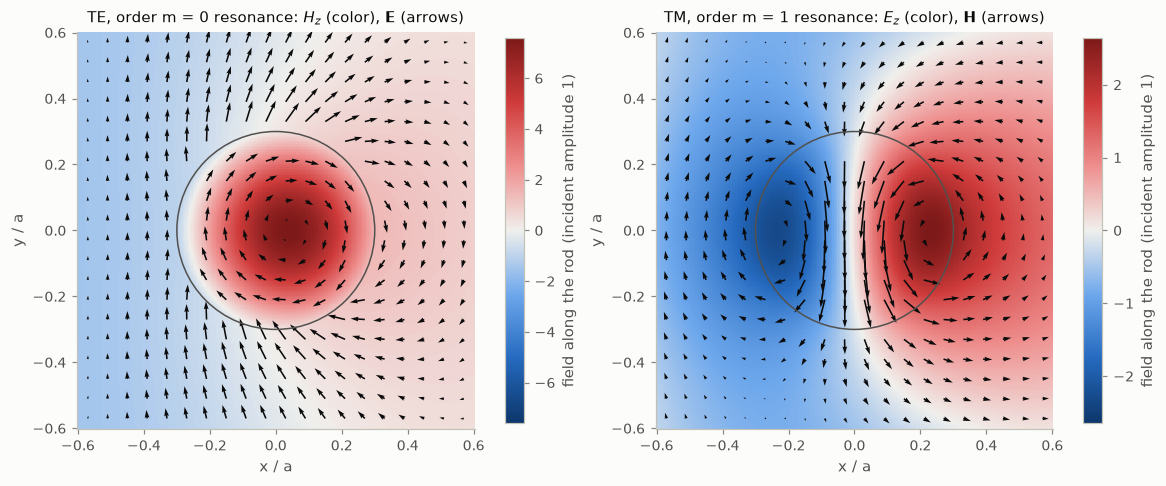

In [4]:
def rod_field(k0, eps, pol, X, Y, M=8):
    """Total field u and the in-plane partner field for a plane wave exp(i k0 x) on one rod at the origin."""
    l = np.arange(-M, M + 1)
    a = 1j ** l
    b = rl.mie_t(l, k0, R, eps, pol) * a
    k1 = k0 * np.sqrt(eps)
    c = (a * jv(l, k0 * R) + b * hankel1(l, k0 * R)) / jv(l, k1 * R)
    r, ph = np.hypot(X, Y), np.arctan2(Y, X)
    inside = r < R
    u = np.zeros(X.shape, complex)
    for li, ai, bi, ci in zip(l, a, b, c):
        u += np.where(inside, ci * jv(li, k1 * r), ai * jv(li, k0 * r) + bi * hankel1(li, k0 * np.maximum(r, R))) * np.exp(1j * li * ph)
    h = X[0, 1] - X[0, 0]
    uy, ux = np.gradient(u, h)
    if pol == "TE":                                  # E = (i / (k0 eps)) curl(H z)
        s = 1j / (k0 * np.where(inside, eps, 1.0))
    else:                                            # H = (-i / k0) curl(E z)
        s = -1j / k0
    return u, s * uy, -s * ux, inside


g = np.linspace(-0.6, 0.6, 241)
X, Y = np.meshgrid(g, g)
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.6))
for ax, pol, m, lab in ((axs[0], "TE", 0, r"$H_z$ (color), $\mathbf{E}$ (arrows)"), (axs[1], "TM", 1, r"$E_z$ (color), $\mathbf{H}$ (arrows)")):
    k0 = res[12.0][0 if pol == "TE" else 1] / (np.sqrt(12.0) * R)
    u, vx, vy, inside = rod_field(k0, 12.0, pol, X, Y)
    phase = np.exp(-1j * np.angle(u[np.unravel_index(np.argmax(np.abs(u)), u.shape)]))      # snapshot at the maximum of the resonant field
    lim = np.abs(u).max()
    im = ax.pcolormesh(X, Y, (u * phase).real, cmap=DIV, vmin=-lim, vmax=lim, shading="auto", rasterized=True)
    edge = np.abs(np.hypot(X, Y) - R) < 0.03                                               # finite differences are wrong across the interface
    sk = (slice(6, None, 12), slice(6, None, 12))
    q = 1j * phase                                                                          # the partner field is in quadrature
    vxr, vyr = np.where(edge, np.nan, (vx * q).real), np.where(edge, np.nan, (vy * q).real)
    ax.quiver(X[sk], Y[sk], vxr[sk], vyr[sk], color=INK, width=0.004, scale=None)
    ax.add_patch(plt.Circle((0, 0), R, fill=False, color=INK2, lw=1))
    ax.set(aspect="equal", xlabel="x / a", ylabel="y / a", title=f"{pol}, order m = {m} resonance: {lab}")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="field along the rod (incident amplitude 1)")
plt.show()

## 2. Lattice sums

In the lattice each rod is illuminated by the waves scattered from all the others. With Bloch vector $\mathbf k_B$ the coefficients on every rod are those of the rod at the origin times $e^{i\mathbf k_B\cdot\mathbf R}$, and Graf's addition theorem turns the outgoing waves of the other rods into regular waves at the origin:

$$a_l=\sum_mG_{l-m}\,b_m,\qquad G_n(k_0,\mathbf k_B)=\sum_{\mathbf R\ne0}H_n(k_0R)\,e^{-in\varphi_{\mathbf R}}\,e^{i\mathbf k_B\cdot\mathbf R}.$$

The sums converge conditionally and are not computed this way. Equivalently, $G_n$ are the coefficients of the regular part of the field of a lattice of monopoles, $\sum_{\mathbf R\neq0}e^{i\mathbf k_B\cdot\mathbf R}H_0(k_0|\mathbf r-\mathbf R|)=\sum_nG_nJ_n(k_0r)e^{in\varphi}$. Writing the lattice as a stack of line arrays and each line array as a sum of plane waves (Poisson summation along the array, then a geometric series over the arrays) gives, for $|x|<a$,

$$\sum_{\mathbf R}e^{i\mathbf k_B\cdot\mathbf R}H_0(k_0|\mathbf r-\mathbf R|)=\frac2a\sum_p\frac{e^{ik_{y,p}y}}{k_{x,p}}\Big[e^{ik_{x,p}|x|}+\frac{e^{ik_{x,p}(a-x)}e^{ik_{Bx}a}}{1-e^{i(k_{x,p}+k_{Bx})a}}+\frac{e^{ik_{x,p}(a+x)}e^{-ik_{Bx}a}}{1-e^{i(k_{x,p}-k_{Bx})a}}\Big],$$

with $k_{y,p}=k_{By}+2\pi p/a$ and $k_{x,p}=\sqrt{k_0^2-k_{y,p}^2}$. The bracket is even in $k_{x,p}$, so the sum is a meromorphic function of $k_0$ and $\mathbf k_B$ with poles on the empty-lattice light cones, and the terms decay exponentially in $p$ away from the line $x=0$. `rodlattice.lattice_sums` samples this field on a circle of radius $\xi<a/2$ around the origin, using for each sample the stacking direction (along $x$ or along $y$) in which it is farther from the line through the origin, subtracts the monopole at the origin, and projects on $e^{in\varphi}$. The same projection applied to one line array gives the sums needed for slabs in notebook 04.

For complex $k_0$ with a positive imaginary part the defining sums converge exponentially and can be evaluated by brute force. This is the check, for the lattice and for one line array.

In [5]:
print("relative error of G_n, n = -8..8, against brute-force sums at complex k0:")
worst = 0.0
for k0, kB in [(2.0 + 0.5j, (0.7, 0.3)), (3.5 + 0.4j, (1.9, 0.0)), (1.0 + 0.6j, (0.4, 0.4)), (4.2 + 0.5j, (2.0, 1.1))]:
    err = np.abs(rl.lattice_sums(k0, kB, 8) / rl.direct_lattice_sums(k0, kB, 8, nmax=90) - 1).max()
    worst = max(worst, err)
    print(f"  lattice,    k0 = {k0}, kB = {kB}: {err:.1e}")
check("square-lattice sums against brute force", worst, 1e-9)
worst = 0.0
for k0, ky in [(2.0 + 0.3j, 0.7), (3.5 + 0.2j, 1.9), (4.2 + 0.3j, 2.0)]:
    err = np.abs(rl.column_sums(k0, ky, 8) / rl.direct_lattice_sums(k0, (0.0, ky), 8, nmax=400, column=True) - 1).max()
    worst = max(worst, err)
    print(f"  line array, k0 = {k0}, ky = {ky}: {err:.1e}")
check("line-array sums against brute force", worst, 1e-9)

# real frequency: the structure used for the Bloch condition, and the cost
G = rl.lattice_sums(2.3, (0.9, 0.4), 8)
N = (G + (np.arange(-8, 9) == 0)) / 1j
check("real k0: G_n = -delta_n0 + i N_n with conj(N_n) = N_-n", np.abs(np.conj(N) - N[::-1]).max(), 1e-9)
ref = rl.lattice_sums(2.3, (0.9, 0.4), 8, nphi=128, pmax=60)
check("converged in the number of samples and plane waves (relative)", np.abs(G / ref - 1).max(), 1e-10)
t0 = time.perf_counter()
for _ in range(200):
    rl.lattice_sums(2.3, (0.9, 0.4), 8)
print(f"one evaluation of the 17 sums: {(time.perf_counter() - t0) / 200 * 1e3:.2f} ms")

relative error of G_n, n = -8..8, against brute-force sums at complex k0:
  lattice,    k0 = (2+0.5j), kB = (0.7, 0.3): 1.5e-12


  lattice,    k0 = (3.5+0.4j), kB = (1.9, 0.0): 4.1e-13
  lattice,    k0 = (1+0.6j), kB = (0.4, 0.4): 2.5e-11


  lattice,    k0 = (4.2+0.5j), kB = (2.0, 1.1): 4.7e-12
PASS  square-lattice sums against brute force: got 2.51732e-11, target 0, |diff| 2.52e-11 <= 1e-09
  line array, k0 = (2+0.3j), ky = 0.7: 8.3e-13
  line array, k0 = (3.5+0.2j), ky = 1.9: 1.0e-12
  line array, k0 = (4.2+0.3j), ky = 2.0: 1.5e-12
PASS  line-array sums against brute force: got 1.50208e-12, target 0, |diff| 1.50e-12 <= 1e-09
PASS  real k0: G_n = -delta_n0 + i N_n with conj(N_n) = N_-n: got 1.5198e-10, target 0, |diff| 1.52e-10 <= 1e-09
PASS  converged in the number of samples and plane waves (relative): got 1.07506e-12, target 0, |diff| 1.08e-12 <= 1e-10
one evaluation of the 17 sums: 0.25 ms


## 3. Bloch modes

Without an external source $b=Ta$ and $a=Gb$, so a Bloch mode exists where $I-TG$ is singular ($T=\mathrm{diag}\,t_l$, $G=[G_{l-m}]$). For a lossless rod and real $k_0$, $\mathbf k_B$ away from the light cones this determinant can be made real. With $t_l=-p_l/(p_l+iq_l)$ and $G=-I+iN$, $N$ Hermitian,

$$I-TG=i\,(P+iQ)^{-1}\,(Q+PN),$$

so the modes are the zeros of the Hermitian matrix $P^{-1}Q+N$. Counting its negative eigenvalues along a frequency scan locates the modes with their multiplicity; an eigenvalue that changes sign through infinity (at $p_l=0$ or at a light cone) is discarded. `rodlattice.bloch_frequencies` does this.

**Check against plane waves.** For TM the plane-wave expansion is a Hermitian generalized eigenproblem, $|\mathbf k+\mathbf G|^2E_{\mathbf G}=k_0^2\sum_{\mathbf G'}\varepsilon_{\mathbf G-\mathbf G'}E_{\mathbf G'}$, with the Fourier coefficients of the rod known in closed form, and it converges well. For TE the standard form with the inverse of the permittivity matrix converges slowly, from below, because the field normal to the rod surface is discontinuous; the check there is looser and shows the trend.

In [6]:
def pw_setup(nmax):
    g = TWO_PI * np.arange(-nmax, nmax + 1)
    GX, GY = [v.ravel() for v in np.meshgrid(g, g, indexing="ij")]
    Q = np.hypot(GX[:, None] - GX[None, :], GY[:, None] - GY[None, :])
    return GX, GY, Q


def pw_bands(kB, radius, eps, pol, nmax=12, nb=4):
    """Lowest a/lambda0 at Bloch vector kB from a plane-wave expansion with (2 nmax + 1)^2 waves."""
    GX, GY, Q = pw_setup(nmax)
    S = np.where(Q > 1e-12, TWO_PI * radius * j1(Q * radius) / np.where(Q > 1e-12, Q, 1.0), np.pi * radius**2)   # indicator of the rod
    epsm = np.eye(len(GX)) + (eps - 1) * S
    kx, ky = kB[0] + GX, kB[1] + GY
    if pol == "TM":
        w2 = eigh(np.diag(kx**2 + ky**2), epsm, eigvals_only=True, subset_by_index=[0, nb - 1])
    else:
        w2 = np.linalg.eigvalsh((kx[:, None] * kx[None, :] + ky[:, None] * ky[None, :]) * np.linalg.inv(epsm))[:nb]
    return np.sqrt(np.abs(w2)) / TWO_PI


print("TM, R = 0.2, eps_r = 8.9 (alumina rods): multiple scattering against plane waves (nmax = 14)")
worst = 0.0
for kB in [(0.3, 0.0), (np.pi, 0.0), (np.pi, np.pi), (1.5, 1.5), (2.0, 0.7)]:
    ms = rl.bloch_frequencies(kB, 0.2, 8.9, "TM", M=3, fmax=0.8)[:4]
    pw = pw_bands(kB, 0.2, 8.9, "TM", 14, 4)
    worst = max(worst, np.abs(ms - pw).max())
    print(f"  kB = ({kB[0]:.3f}, {kB[1]:.3f}):  MS {np.round(ms, 5)}   PW {np.round(pw, 5)}")
check("TM bands: multiple scattering vs plane waves (max |difference| in a/lambda0)", worst, 1e-4)
print("the degenerate pair at M is found twice, as it should be.")

print("\nTE, same lattice: plane waves converge slowly (nmax = 8, 12, 16) toward the multiple-scattering value")
kB = (np.pi, 0.0)
ms = rl.bloch_frequencies(kB, 0.2, 8.9, "TE", M=3, fmax=0.6)[0]
pws = [pw_bands(kB, 0.2, 8.9, "TE", nm, 1)[0] for nm in (8, 12, 16)]
print(f"  first band at X: MS {ms:.5f}   PW {np.round(pws, 5)}")
check("TE first band at X: plane waves (nmax = 16) within 1.5 percent of multiple scattering", (ms - pws[-1]) / ms, 0.015)
assert pws[0] < pws[1] < pws[2] < ms
mM = rl.bloch_frequencies((np.pi, np.pi), 0.2, 8.9, "TE", M=3, fmax=0.58)[0]
check("TE first band at M (a mode the plane-wave series resolves well)", mM, 5e-5, pw_bands((np.pi, np.pi), 0.2, 8.9, "TE", 14, 1)[0])

print("\nconvergence in the multipole order M (frequencies at X, eps_r = 12, R = 0.3):")
for pol in ("TM", "TE"):
    for M in (1, 2, 3, 4, 5):
        print(f"  {pol} M = {M}: {np.round(rl.bloch_frequencies((np.pi, 0.0), R, 12.0, pol, M=M, fmax=0.5)[:3], 5)}")
m3, m5 = (rl.bloch_frequencies((np.pi, 0.0), R, 12.0, "TE", M=M, fmax=0.5)[:3] for M in (3, 5))
check("TE at X: M = 3 against M = 5", np.abs(m3 - m5).max(), 5e-5)

TM, R = 0.2, eps_r = 8.9 (alumina rods): multiple scattering against plane waves (nmax = 14)


  kB = (0.300, 0.000):  MS [0.03379 0.57751 0.62798 0.63206]   PW [0.03379 0.57751 0.62801 0.63209]


  kB = (3.142, 0.000):  MS [0.27471 0.44252 0.63595 0.77223]   PW [0.27471 0.44253 0.63599 0.77226]


  kB = (3.142, 3.142):  MS [0.32239 0.54883 0.54883 0.69359]   PW [0.3224  0.54885 0.54885 0.6936 ]


  kB = (1.500, 1.500):  MS [0.22362 0.51831 0.5903  0.71857]   PW [0.22363 0.51832 0.59032 0.71859]


  kB = (2.000, 0.700):  MS [0.22296 0.49284 0.61833 0.71721]   PW [0.22296 0.49285 0.61836 0.71723]
PASS  TM bands: multiple scattering vs plane waves (max |difference| in a/lambda0): got 3.45531e-05, target 0, |diff| 3.46e-05 <= 1e-04
the degenerate pair at M is found twice, as it should be.

TE, same lattice: plane waves converge slowly (nmax = 8, 12, 16) toward the multiple-scattering value


... (3 outputs left out)

  TM M = 5: [0.19198 0.30083 0.40769]
  TE M = 1: [0.33413 0.34098]


  TE M = 2: [0.33146 0.34098]
  TE M = 3: [0.33146 0.34062]


  TE M = 4: [0.33146 0.34062]
  TE M = 5: [0.33146 0.34062]


PASS  TE at X: M = 3 against M = 5: got 6.08236e-06, target 0, |diff| 6.08e-06 <= 5e-05


## 4. Band structures

Bands along $\Gamma\to X\to M\to\Gamma$ for three cases: TE and TM with $\varepsilon_r=12$, and TE with $\varepsilon_r=100$. The dashed line in each panel is the frequency of the single-rod magnetic resonance of section 1.

three band structures: 31 s


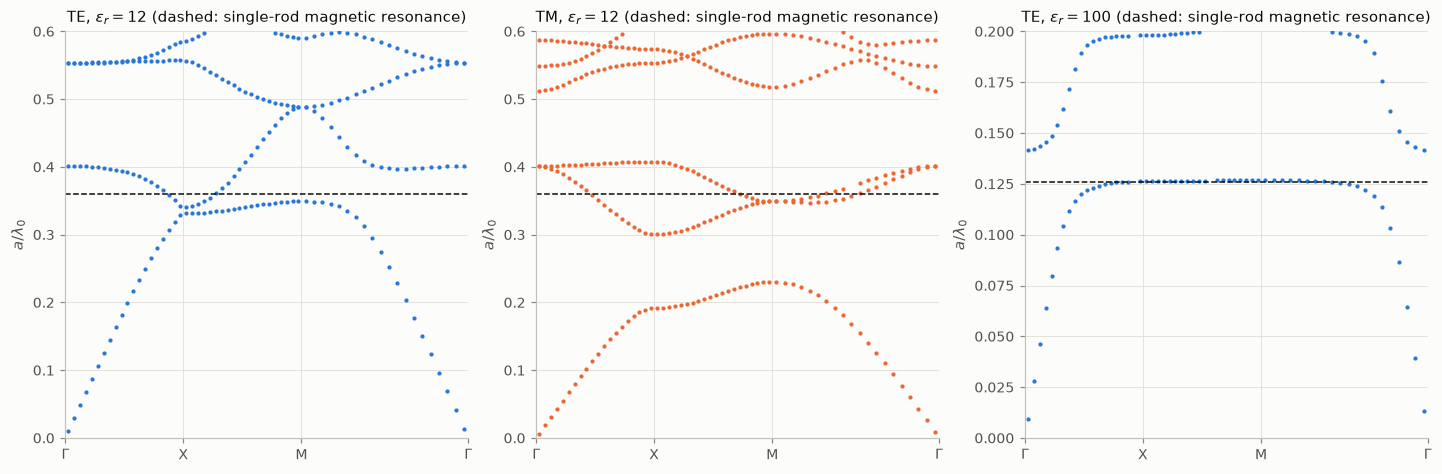

modes at the symmetry points (a/lambda0), from separate fine scans:


  TE, eps_r = 12: near Gamma: [0.4016];  X: [0.3315 0.3406];  M: [0.3495]


  TM, eps_r = 12: near Gamma: [0.4016 0.4016];  X: [0.192  0.3008 0.4077];  M: [0.2305 0.3494 0.3494]


  TE, eps_r = 100: near Gamma: [0.1417];  X: [0.1263];  M: [0.1268]
TE, eps_r = 100: the first band tops out at 0.1268 (at X or M) and the next band starts at Gamma at 0.1417
single-rod resonance: 0.1258, i.e. 0.8 percent below the top of the first band
PASS  TE, eps_r = 100: the first band tops out just above the single-rod resonance (relative distance): got 0.00848067, target 0.01, |diff| 1.52e-03 <= 1e-02
eps_r = 12 at Gamma: TE 0.401632, TM pair 0.401554, 0.401554;  at M: TE 0.349483, TM pair 0.349398, 0.349398
PASS  the TE singlet and the TM doublet nearly coincide at Gamma (relative difference): got -0.000195978, target 0, |diff| 1.96e-04 <= 1e-03


In [7]:
def band_path(eps, pol, fmax, npts=20, nscan=500, M=3):
    """Bloch frequencies along Gamma-X-M-Gamma. Returns (path coordinate, frequency) pairs and the tick positions."""
    corners = [np.array(c) for c in ((0.0, 0.0), (np.pi, 0.0), (np.pi, np.pi), (0.0, 0.0))]
    s0, xs, fs = 0.0, [], []
    ticks = [0.0]
    for c0, c1 in zip(corners[:-1], corners[1:]):
        seg = np.linalg.norm(c1 - c0)
        for u in (np.arange(npts) + 0.5) / npts:         # midpoints: avoids the symmetry points and their light-cone poles
            kB = c0 + u * (c1 - c0)
            for f in rl.bloch_frequencies(tuple(kB), R, eps, pol, M=M, fmax=fmax, nscan=nscan):
                xs.append(s0 + u * seg); fs.append(f)
        s0 += seg; ticks.append(s0)
    return np.array(xs), np.array(fs), ticks


t0 = time.perf_counter()
cases = [("TE", 12.0, 0.6), ("TM", 12.0, 0.6), ("TE", 100.0, 0.2)]
bands = {(pol, eps): band_path(eps, pol, fmax) for pol, eps, fmax in cases}
print(f"three band structures: {time.perf_counter() - t0:.0f} s")

fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (pol, eps, fmax) in zip(axs, cases):
    xs, fs, ticks = bands[(pol, eps)]
    ax.plot(xs, fs, ".", ms=3.5, color=CAT[0] if pol == "TE" else CAT[1])
    fr = res[eps][0 if pol == "TE" else 1] / (TWO_PI * np.sqrt(eps) * R)
    ax.axhline(fr, color=INK, ls="--", lw=1)
    ax.set_xticks(ticks, [r"$\Gamma$", "X", "M", r"$\Gamma$"]); ax.set_xlim(ticks[0], ticks[-1]); ax.set_ylim(0, fmax)
    ax.set(ylabel=r"$a/\lambda_0$", title=rf"{pol}, $\varepsilon_r={eps:g}$ (dashed: single-rod magnetic resonance)")
plt.show()

print("modes at the symmetry points (a/lambda0), from separate fine scans:")
sym_modes = {}
for pol, eps, fmax in cases:
    pts = {"near Gamma": (1e-3, 0.0), "X": (np.pi, 0.0), "M": (np.pi, np.pi)}
    sym_modes[(pol, eps)] = {name: rl.bloch_frequencies(kB, R, eps, pol, M=4, fmax=fmax * 0.75, nscan=1500) for name, kB in pts.items()}
    print(f"  {pol}, eps_r = {eps:g}: " + ";  ".join(f"{name}: {np.round(v, 4)}" for name, v in sym_modes[(pol, eps)].items()))
te100 = sym_modes[("TE", 100.0)]
gap_lo = max(te100["X"][0], te100["M"][0]); gap_hi = te100["near Gamma"][te100["near Gamma"] > 0.05].min()
print(f"TE, eps_r = 100: the first band tops out at {gap_lo:.4f} (at X or M) and the next band starts at Gamma at {gap_hi:.4f}")
print(f"single-rod resonance: {F_RES[100.0]:.4f}, i.e. {100 * (gap_lo / F_RES[100.0] - 1):.1f} percent below the top of the first band")
check("TE, eps_r = 100: the first band tops out just above the single-rod resonance (relative distance)", gap_lo / F_RES[100.0] - 1, 0.01, 0.01)
te12, tm12 = sym_modes[("TE", 12.0)], sym_modes[("TM", 12.0)]
print(f"eps_r = 12 at Gamma: TE {te12['near Gamma'][0]:.6f}, TM pair {tm12['near Gamma'][0]:.6f}, {tm12['near Gamma'][1]:.6f};  at M: TE {te12['M'][0]:.6f}, TM pair {tm12['M'][1]:.6f}, {tm12['M'][2]:.6f}")
check("the TE singlet and the TM doublet nearly coincide at Gamma (relative difference)", tm12["near Gamma"][0] / te12["near Gamma"][0] - 1, 1e-3)

Three different situations.

- **TE, $\varepsilon_r=12$.** The first band reaches the zone boundary before the resonance: at $X$ the Bloch wavelength is two periods at a frequency below the dashed line. The resonance shows up as a flat band that the first band meets near $X$ and $M$; at $X$ the two are split by a small amount and along the rest of the path they overlap in frequency, so there is no gap. Whether one reads the structure near $X$ as Bragg scattering or as magnetism is a matter of taste.
- **TM, $\varepsilon_r=12$.** The electric response along the rods makes the index large from the start, so the first band already ends near $a/\lambda_0=0.2$, well below the resonance, and a wide gap follows. Whatever happens at the magnetic resonance happens at large Bloch wavenumber.
- **TE, $\varepsilon_r=100$.** The resonance is at a vacuum wavelength of about eight periods. The first band bends over and flattens as it approaches it, a gap opens, and a second band starts at $\Gamma$ above the gap: the shape a resonant permeability gives, with $\mu<0$ in the gap. The single-rod resonance lies just below the top of the first band, not inside the gap: the gap runs from just below the pole of the lattice's permeability, which is slightly above the single-rod resonance, to its zero (notebook 03 computes the pole; the zero is the mode at $\Gamma$ printed above).

A curiosity in the printed modes: for $\varepsilon_r=12$ the TE mode at $\Gamma$ and the TM pair at $\Gamma$ have almost the same frequency, and the same happens at $M$. This is the identity $t^{\rm TE}_0=t^{\rm TM}_1$ at work. If $u$ is a TE field with only the $m=0$ harmonic around every rod, its electric field is purely azimuthal there, and each Cartesian component of that field is continuous with a continuous normal derivative across the rod surface, so it is a TM solution with $m=\pm1$ character. At $\Gamma$ and $M$ the TE mode in question contains only the harmonics $m=0,\pm4,\dots$, and the map fails only through the small $m=\pm4$ part.

## 5. The textbook local model against the bands

For TE the simplest effective-medium description is a static permittivity and the permeability of O'Brien and Pendry. With $\mathbf H$ along the rods and the wavelength outside the rods long, the magnetic field outside is uniform and the field inside is $J_0(k_1r)/J_0(k_1R)$ times it, so the cell average of $B$ over the outside $H$ is

$$\mu_{\rm OBP}(\omega)=1-\eta+\eta\,\frac{2J_1(x)}{x\,J_0(x)},\qquad x=k_0R\sqrt{\varepsilon_r},\qquad\eta=\frac{\pi R^2}{a^2}\ \text{(filling fraction)},$$

with a pole at the zero of $J_0$ and no Lorentz shift, because the depolarizing factor along the axis is zero. The transverse static permittivity of a square array of cylinders is Rayleigh's series, $\varepsilon_{\rm st}=1+2\eta/\big(\beta^{-1}-\eta-0.3058\,\beta\eta^4-\dots\big)$ with $\beta=(\varepsilon_r-1)/(\varepsilon_r+1)$. The model is $k=k_0\sqrt{\varepsilon_{\rm st}\,\mu_{\rm OBP}}$.

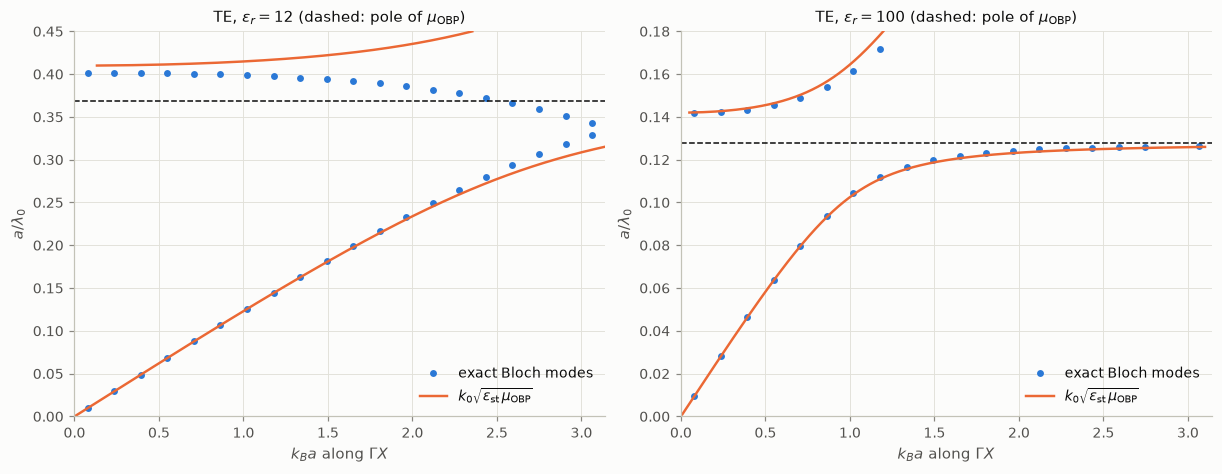

 eps_r   first band near X (exact)   model reaches k = pi   pole of mu_OBP   exact / model at X
    12         0.3291                    0.3153              0.3683           1.044
   100         0.1263                    0.1260              0.1276           1.002
PASS  eps_r = 100: the model reaches the zone boundary at X within 3 percent of the exact frequency there: got 1.00191, target 1, |diff| 1.91e-03 <= 3e-02


In [8]:
def mu_obp(f, eps):
    x = TWO_PI * f * np.sqrt(eps) * R
    return 1 - FILL + FILL * 2 * jv(1, x) / (x * jv(0, x))


def eps_rayleigh(eps):
    b = (eps - 1) / (eps + 1)
    return 1 + 2 * FILL / (1 / b - FILL - 0.305827 * b * FILL**4 - 0.013362 * b * FILL**8)


fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
summary = {}
for ax, eps, fmax in ((axs[0], 12.0, 0.45), (axs[1], 100.0, 0.18)):
    xs, fs, ticks = bands[("TE", eps)]
    sel = (xs < ticks[1]) & (fs < fmax)
    ax.plot(xs[sel], fs[sel], "o", ms=3.5, color=CAT[0], label="exact Bloch modes")
    ff = np.linspace(1e-3, fmax, 3000)
    k2 = (TWO_PI * ff) ** 2 * eps_rayleigh(eps) * mu_obp(ff, eps)
    kloc = np.sqrt(np.where(k2 > 0, k2, np.nan))
    kloc[kloc > np.pi] = np.nan
    ax.plot(kloc, ff, color=CAT[1], label=r"$k_0\sqrt{\varepsilon_{\rm st}\,\mu_{\rm OBP}}$")
    f_pole = J0_ZERO / (TWO_PI * np.sqrt(eps) * R)
    ax.axhline(f_pole, color=INK, ls="--", lw=1)
    ax.set(xlabel=r"$k_B a$ along $\Gamma X$", ylabel=r"$a/\lambda_0$", xlim=(0, np.pi), ylim=(0, fmax),
           title=rf"TE, $\varepsilon_r={eps:g}$ (dashed: pole of $\mu_{{\rm OBP}}$)")
    ax.legend(loc="lower right")
    # where the first band and the model reach the zone boundary, and the lower edge of the second band on Gamma X
    first_X = fs[sel & (xs > 0.95 * np.pi)].min()
    model_X = ff[np.nanargmax(np.where(ff < f_pole, k2, np.nan) > np.pi**2)]
    summary[eps] = (first_X, model_X, f_pole)
plt.show()
print(" eps_r   first band near X (exact)   model reaches k = pi   pole of mu_OBP   exact / model at X")
for eps, (fx, fm, fp) in summary.items():
    print(f"{eps:6.0f}   {fx:12.4f}              {fm:12.4f}        {fp:12.4f}      {fx / fm:10.3f}")
check("eps_r = 100: the model reaches the zone boundary at X within 3 percent of the exact frequency there", summary[100.0][0] / summary[100.0][1], 0.03, 1.0)

For $\varepsilon_r=100$ the local model follows the first band across the whole zone, bends over with it, places the gap, and starts the upper branch at $\Gamma$ at the right frequency. For $\varepsilon_r=12$ the model is good in the lower half of the first band and then overestimates the wavenumber, so it reaches the zone boundary at a lower frequency than the exact band; both do so below the pole of $\mu_{\rm OBP}$. Its upper branch starts near the exact flat band at $\Gamma$ but disperses upward, while the exact band disperses downward. The printed table has the numbers.

One point matters for everything that follows. Near a resonance of $\mu$ the model itself says $k\to\infty$, so the wave explores large $k$ exactly where the permeability is interesting, and "small $ka$" is lost at the frequencies one cares about, however small $a/\lambda_0$ is. Spatial dispersion beyond second order is not an accident of a low permittivity. Raising $\varepsilon_r$ narrows the frequency window in which this happens; it does not remove it.

## Summary

- **Rod.** The magnetic dipoles are $m=0$ in TE and $m=\pm1$ in TM, with identical scattering coefficients, resonant near $k_0R\sqrt{\varepsilon_r}=2.4$.
- **Solver.** Lattice sums agree with brute-force sums to the printed accuracy; the Hermitian mode condition finds the plane-wave bands, with multiplicity, for TM, and is the limit the slowly convergent plane-wave series approaches for TE.
- **Bands.** $\varepsilon_r=12$ puts the magnetic resonance at the zone boundary (TE) or above the first band and its gap (TM). $\varepsilon_r=100$ in TE gives the textbook picture: flattening band, gap, upper band from $\Gamma$.
- **Local model.** The O'Brien-Pendry permeability with a static permittivity describes the $\varepsilon_r=100$ bands along $\Gamma X$ well and the $\varepsilon_r=12$ bands only at low frequency.

## Caveats and open ends

- The bands are sampled on one path, and a mode within a scan step of a pole of the mode condition can be missed. The band figures are for orientation; the quantitative statements of notebooks 03 and 04 do not rest on them.
- Lossless rods only in this notebook. Notebook 04 adds loss.
- Circular rods on a square lattice. Other lattices change the lattice sums only; other shapes would need a different single-scatterer solver.

## References

- S. O'Brien and J. B. Pendry, J. Phys.: Condens. Matter 14, 4035 (2002), magnetic activity of dielectric rod arrays.
- L. Peng et al., Phys. Rev. Lett. 98, 157403 (2007), dielectric rods with $\mathbf E$ along the axis.
- Lord Rayleigh, Philos. Mag. 34, 481 (1892); W. T. Perrins, D. R. McKenzie and R. C. McPhedran, Proc. R. Soc. A 369, 207 (1979), for the static series.
- C. M. Linton, SIAM Review 52, 630 (2010), lattice sums for the Helmholtz equation.
- J. D. Joannopoulos, S. G. Johnson, J. N. Winn and R. D. Meade, *Photonic Crystals: Molding the Flow of Light*, 2nd ed., for the alumina-rod lattice used as a check.